# Error Analysis Pipeline — Dialogue Summarization (Margin Contrastive Learning)

Notebook ini menjalankan **error analysis end-to-end** untuk eksperimen ringkasan dialog
(BART method 1–4, Qwen method 6–9) dengan teknik *margin contrastive learning*.

**Alur (sesuai panduan):**

| Tahap | Isi | Otomatis? |
|------|-----|-----------|
| 0 | Validasi integritas metrik | ✅ |
| 1 | Profil distribusi & korelasi | ✅ |
| 2 | Stratifikasi (panjang/domain/turns) + uji beda | ✅ |
| 3 | Sampling terstratifikasi untuk inspeksi | ✅ |
| 4 | Taksonomi error & anotasi | ⚠️ **manual** (sel placeholder, tidak dijalankan) |
| 5 | Perbandingan antar-eksperimen | ✅ (metrik) + ⚠️ (error rate butuh Tahap 4) |
| 6 | Diagnosis margin contrastive | ⚠️ **manual** (audit negative sample) |
| 7 | Sintesis & pelaporan | ✅ (ekspor) + ⚠️ (narasi) |

> Sel bertanda **MANUAL — JANGAN JALANKAN** sengaja dibiarkan tidak dieksekusi karena
> memerlukan penilaian manusia (membaca ringkasan, melabeli tipe error, mengaudit data training).
> Sel tersebut berisi *scaffold* siap-isi, bukan kode yang harus dijalankan apa adanya.

**Catatan path:** notebook ini memakai loader yang sama dengan notebook analisis Anda
(`{method}_outputs/{split}/...json` + `configs/...`). Sesuaikan `EXPERIMENTS` & `DIALOG_PATH` di sel KONFIG.


## Tahap Setup — Konfigurasi & Loader

In [1]:
# ===================== KONFIG =====================
# Daftar eksperimen yang dianalisis. Key = label bebas; value = (method_num, split_path).
# Tambah/hapus sesuai eksperimen Anda. Baseline non-contrastive WAJIB ada untuk perbandingan Tahap 5.
EXPERIMENTS = {
    # label              method_num   split_path
    "BART-m4":          ("method4",  "bart_margin_full"),
    # "BART-baseline":  ("method3",  "bart_part"),          # <- contoh baseline non-contrastive
    # "Qwen-m7":        ("method7",  "qwen_margin_part"),
    # "Qwen-m8":        ("method8",  "qwen_margin_part"),
}

DIALOG_PATH   = "data/all_dialogue_test_500.json"  # file dialog test (sejajar urutan dgn hasil)
DIALOG_TEXT_COL = 0          # kolom teks dialog di DIALOG_PATH
N_LEN_BINS    = 3            # short / medium / long
ARTIFACT_NEAR_ZERO = 0.20    # ambang flag artefak metrik (Tahap 0)
K_SAMPLES     = 12           # jumlah contoh per kelompok diagnostik (Tahap 3)
RANDOM_SEED   = 42
OUTPUT_DIR    = "error_analysis_outputs"
# ==================================================

import os
os.makedirs(OUTPUT_DIR, exist_ok=True)
print("Eksperimen:", list(EXPERIMENTS))


Eksperimen: ['BART-m4']


In [2]:
import json, re, warnings, textwrap
from pathlib import Path
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from scipy.stats import f_oneway, kruskal, spearmanr

warnings.filterwarnings("ignore")
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
np.random.seed(RANDOM_SEED)

# ---------- loader (kompatibel dgn notebook analisis Anda) ----------
def load_yaml(path):
    p = Path(path)
    if not p.is_file():
        raise FileNotFoundError(f"Config tidak ditemukan: {p}")
    with open(p, "r", encoding="utf-8") as f:
        return yaml.safe_load(f) or {}

def load_json(path):
    p = Path(path)
    if not p.is_file():
        raise FileNotFoundError(f"JSON tidak ditemukan: {p}")
    with open(p, "r", encoding="utf-8") as f:
        return json.load(f)

def get_rouge_score(method_num, path):
    return load_json(Path(f"{method_num}_outputs") / path / "rouge.json")

def get_generated_file(method_num, path):
    data = load_json(Path(f"{method_num}_outputs") / path / "generated.json")
    return {key: [d[key] for d in data] for key in data[0]}

def reformat_unieval(unieval):
    if not unieval:
        return {}
    keys = ["coherence", "relevance", "fluency", "consistency"]
    return {k: [item.get(k, np.nan) for item in unieval] for k in keys}

def get_unieval_score(method_num, path):
    return reformat_unieval(load_json(Path(f"{method_num}_outputs") / path / "unieval.json"))

def get_align_score(method_num, path):
    return {"align_score": load_json(Path(f"{method_num}_outputs") / path / "alignscore.json")}

def read_result(method_num, path):
    # Satu baris per dialog: skor + prompt/prediction/reference.
    rows = {
        **get_unieval_score(method_num, path),
        **get_align_score(method_num, path),
        **get_generated_file(method_num, path),
    }
    return pd.DataFrame(rows)

METRIC_COLS = ["coherence", "relevance", "fluency", "consistency", "align_score"]
print("Loader siap. Metrik:", METRIC_COLS)


Loader siap. Metrik: ['coherence', 'relevance', 'fluency', 'consistency', 'align_score']


In [3]:
# ---------- deteksi domain & fitur dialog ----------
DOMAIN_KEYWORDS = {
    "hotel":      ["hotel", "guesthouse", "guest house", "stay", "room", "lodge", "star"],
    "restaurant": ["restaurant", "eat", "food", "dine", "dinner", "lunch", "cuisine", "table"],
    "taxi":       ["taxi", "cab", "pick me up", "pickup"],
    "train":      ["train", "departure", "arrive by", "leave after", "trainid"],
    "attraction": ["attraction", "museum", "park", "college", "gallery", "nightclub", "theatre"],
}

def detect_domains(text):
    t = str(text).lower()
    return [d for d, kws in DOMAIN_KEYWORDS.items() if any(k in t for k in kws)]

def n_words(text):
    return len(re.findall(r"\w+", str(text)))

def n_turns(text):
    # hitung pergantian giliran berdasar penanda 'user:' / 'agent:'
    return len(re.findall(r"\b(user|agent)\s*:", str(text).lower()))

def load_dialog_texts(n_expected):
    dlg = pd.read_json(DIALOG_PATH)
    col = DIALOG_TEXT_COL if DIALOG_TEXT_COL in dlg.columns else dlg.columns[0]
    texts = dlg[col].astype(str).reset_index(drop=True)
    assert len(texts) == n_expected, (
        f"Jumlah dialog ({len(texts)}) != jumlah hasil ({n_expected}); urutan harus sejajar."
    )
    return texts


In [4]:
# ---------- muat SEMUA eksperimen jadi satu dict of DataFrame ----------
def attach_features(df, texts):
    df = df.reset_index(drop=True).copy()
    # jika hasil tidak punya kolom dialog, pakai file terpisah
    auto = [c for c in df.columns if c.lower() in ("dialogue", "dialog", "text", "input", "source", "prompt")]
    src = df[auto[0]].astype(str) if auto else texts
    df["_dialogue"] = src.values
    df["_nwords"]   = src.apply(n_words).values
    df["_nturns"]   = src.apply(n_turns).values
    df["_domains"]  = src.apply(detect_domains).values
    return df

DFS = {}
for label, (mnum, split) in EXPERIMENTS.items():
    try:
        d = read_result(mnum, split)
        texts = load_dialog_texts(len(d))
        DFS[label] = attach_features(d, texts)
        print(f"[OK] {label:16s} baris={len(DFS[label])}  kolom={list(DFS[label].columns)}")
    except FileNotFoundError as e:
        print(f"[SKIP] {label}: {e}")

assert DFS, "Tidak ada eksperimen yang berhasil dimuat. Periksa EXPERIMENTS / path."
PRIMARY = list(DFS)[0]   # eksperimen acuan default untuk analisis per-dialog
print("\nEksperimen acuan (PRIMARY):", PRIMARY)


[OK] BART-m4          baris=499  kolom=['coherence', 'relevance', 'fluency', 'consistency', 'align_score', 'prompt', 'prediction', 'reference', '_dialogue', '_nwords', '_nturns', '_domains']

Eksperimen acuan (PRIMARY): BART-m4


## Tahap 0 — Validasi Integritas Metrik

**Tujuan:** menemukan skor yang merupakan *artefak scorer*, bukan ringkasan buruk, sebelum
angka apa pun dirata-rata. Tiga pemeriksaan:

1. **Outlier mendekati nol** (metrik < `ARTIFACT_NEAR_ZERO`).
2. **Kontradiksi antar-metrik** pada satu baris (mis. coherence≈0 tapi align tinggi).
3. **NaN / panjang ekstrem / prediksi kosong**.

Output: daftar baris tersangka + rekap "sebelum vs sesudah" pembersihan.


In [5]:
def flag_artifacts(df, near_zero=ARTIFACT_NEAR_ZERO):
    f = pd.DataFrame(index=df.index)
    # 1) near-zero pada metrik UniEval
    for m in ["coherence", "relevance", "fluency", "consistency"]:
        f[f"nearzero_{m}"] = df[m] < near_zero
    # 2) kontradiksi: UniEval sangat rendah tetapi align tinggi (gap besar)
    unieval_min = df[["coherence", "relevance", "fluency", "consistency"]].min(axis=1)
    f["contradiction"] = (unieval_min < near_zero) & (df["align_score"] > 0.6)
    # 3) prediksi kosong / sangat pendek
    if "prediction" in df.columns:
        f["empty_pred"] = df["prediction"].astype(str).str.strip().str.len() < 5
    # 4) NaN di metrik mana pun
    f["has_nan"] = df[METRIC_COLS].isna().any(axis=1)
    f["SUSPECT"] = f.any(axis=1)
    return f

print("="*70)
print("LAPORAN ARTEFAK METRIK PER EKSPERIMEN")
print("="*70)
ARTIFACT_FLAGS = {}
for label, df in DFS.items():
    flags = flag_artifacts(df)
    ARTIFACT_FLAGS[label] = flags
    n_sus = int(flags["SUSPECT"].sum())
    print(f"\n[{label}] tersangka artefak: {n_sus}/{len(df)} ({100*n_sus/len(df):.1f}%)")
    detail = {c: int(flags[c].sum()) for c in flags.columns if c != "SUSPECT" and flags[c].sum() > 0}
    if detail:
        for k, v in detail.items():
            print(f"    - {k:22s}: {v}")


LAPORAN ARTEFAK METRIK PER EKSPERIMEN

[BART-m4] tersangka artefak: 18/499 (3.6%)
    - nearzero_coherence    : 11
    - nearzero_relevance    : 14
    - contradiction         : 14


In [6]:
# tampilkan baris tersangka pada eksperimen acuan untuk diperiksa mata
flags = ARTIFACT_FLAGS[PRIMARY]
sus_idx = flags.index[flags["SUSPECT"]]
cols_show = ["_nwords"] + METRIC_COLS + [c for c in ["reference", "prediction"] if c in DFS[PRIMARY].columns]
print(f"{len(sus_idx)} baris tersangka di {PRIMARY} (tampil maks 20):")
DFS[PRIMARY].loc[sus_idx, cols_show].head(20)


18 baris tersangka di BART-m4 (tampil maks 20):


,_nwords,coherence,relevance,fluency,consistency,align_score,reference,prediction
0,59,0.056206,0.266886,0.693817,0.736683,0.788799,User Profile: Traveler looking for budget acco...,Profile: Traveler looking for budget accommoda...
17,264,0.119487,0.804560,0.728520,0.727774,0.915848,User Profile: Traveler planning a sightseeing ...,"Profile: Visitor planning a trip to town, inte..."
52,229,0.904055,0.178669,0.889642,0.907428,0.717850,User Profile: Group traveler (party of 7) arra...,Profile: Traveler going from Broxbourne to Cam...
121,303,0.397536,0.086042,0.733777,0.875250,0.379976,User Profile: Budget-conscious traveler who pr...,Profile: Traveler looking for high-end accommo...
157,134,0.120344,0.109123,0.693132,0.700378,0.895542,User Profile: Traveler planning a group stay i...,Profile: Traveler planning a group stay in Cam...
171,252,0.537704,0.198507,0.688669,0.771408,0.573674,User Profile: \nUser planning an outing that ...,Profile: \nUser planning an outing in the cit...
185,294,0.229031,0.019349,0.741526,0.764538,0.662215,User Profile: Budget-conscious traveler flexib...,Profile: Budget-conscious traveler looking for...
208,244,0.069135,0.133350,0.704388,0.832535,0.707469,User Profile: \nUser planning group dining an...,Profile: \nTraveler planning a trip that incl...
250,305,0.095640,0.228716,0.709463,0.694880,0.753892,User Profile: Traveler from Cambridge seeking ...,Profile: Traveler planning a Monday train trip...
256,184,0.444379,0.115162,0.698485,0.841146,0.899369,User Profile: Traveler planning a trip from Br...,Profile: Traveler planning a Tuesday train tri...


In [7]:
# rekap mean SEBELUM vs SESUDAH membuang artefak (transparansi)
def clean_view(df, flags):
    return df.loc[~flags["SUSPECT"]]

rows = []
for label, df in DFS.items():
    flags = ARTIFACT_FLAGS[label]
    clean = clean_view(df, flags)
    for m in METRIC_COLS:
        rows.append({
            "experiment": label, "metric": m,
            "mean_raw": round(df[m].mean(skipna=True), 4),
            "mean_clean": round(clean[m].mean(skipna=True), 4),
            "median_clean": round(clean[m].median(skipna=True), 4),
            "n_dropped": int(flags["SUSPECT"].sum()),
        })
before_after = pd.DataFrame(rows)
before_after["delta"] = (before_after["mean_clean"] - before_after["mean_raw"]).round(4)
before_after.to_csv(f"{OUTPUT_DIR}/tahap0_before_after.csv", index=False)
before_after


,experiment,metric,mean_raw,mean_clean,median_clean,n_dropped,delta
0,BART-m4,coherence,0.8980,0.9222,0.9569,18,0.0242
1,BART-m4,relevance,0.8819,0.9086,0.9593,18,0.0267
2,BART-m4,fluency,0.8396,0.8447,0.8907,18,0.0051
3,BART-m4,consistency,0.8957,0.9002,0.9235,18,0.0045
4,BART-m4,align_score,0.7789,0.7817,0.7830,18,0.0028


In [8]:
# bangun versi BERSIH yang dipakai tahap berikutnya (tetap simpan yg mentah)
DFS_CLEAN = {label: clean_view(df, ARTIFACT_FLAGS[label]).reset_index(drop=True)
             for label, df in DFS.items()}
print("Versi bersih siap. Jumlah baris per eksperimen:")
for label, df in DFS_CLEAN.items():
    print(f"  {label:16s}: {len(df)}  (dari {len(DFS[label])})")


Versi bersih siap. Jumlah baris per eksperimen:
  BART-m4         : 481  (dari 499)


## Tahap 1 — Profil Distribusi & Korelasi

Memahami sebaran tiap metrik (bukan hanya mean), menetapkan **metrik bottleneck**
(mean terendah + variansi tinggi), dan memeriksa korelasi antar-metrik — khususnya
apakah *fluency* dan *faithfulness (align)* berkorelasi rendah/negatif.


In [9]:
# statistik distribusi (eksperimen acuan)
df = DFS_CLEAN[PRIMARY]
desc = df[METRIC_COLS].describe(percentiles=[.1, .25, .5, .75, .9]).T
desc["range"] = desc["max"] - desc["min"]
print(f"Distribusi metrik — {PRIMARY}")
desc.round(4)


Distribusi metrik — BART-m4


,count,mean,std,min,10%,25%,50%,75%,90%,max,range
coherence,481.0,0.9222,0.1049,0.2979,0.8341,0.9247,0.9569,0.9741,0.9818,0.9905,0.6926
relevance,481.0,0.9086,0.1257,0.2623,0.7407,0.9039,0.9593,0.9782,0.9844,0.9920,0.7297
fluency,481.0,0.8447,0.1096,0.3419,0.7034,0.7889,0.8907,0.9239,0.9364,0.9645,0.6226
consistency,481.0,0.9002,0.0647,0.6059,0.8070,0.8784,0.9235,0.9434,0.9549,0.9687,0.3628
align_score,481.0,0.7817,0.1245,0.3324,0.6120,0.7030,0.7830,0.8871,0.9410,0.9861,0.6536


In [10]:
# identifikasi metrik bottleneck = skor rendah & variansi tinggi
score = (1 - desc["mean"]).rank() + desc["std"].rank()   # makin tinggi = makin "bermasalah"
bottleneck = score.idxmax()
print("Ranking 'kerawanan' metrik (mean rendah + std tinggi):")
print(score.sort_values(ascending=False).round(2).to_string())
print(f"\n>> METRIK BOTTLENECK: {bottleneck}")
BOTTLENECK = bottleneck


Ranking 'kerawanan' metrik (mean rendah + std tinggi):
align_score    9.0
relevance      7.0
fluency        7.0
consistency    4.0
coherence      3.0

>> METRIK BOTTLENECK: align_score


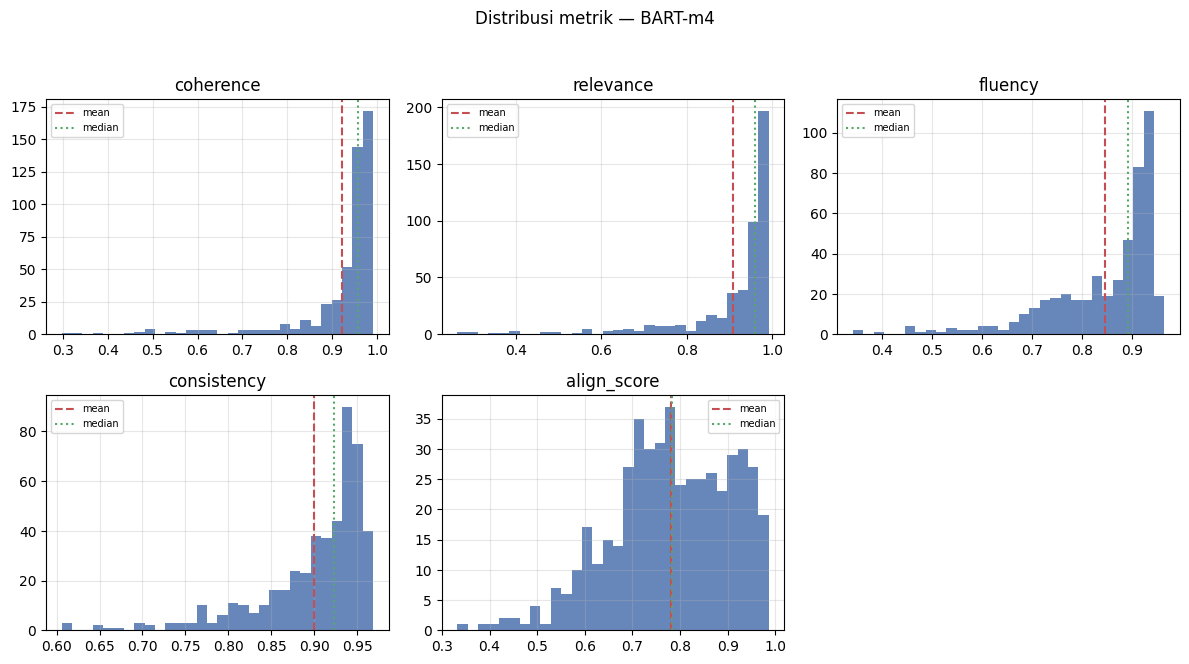

In [32]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6.4)) 
axes_flat = np.ravel(axes) # Meratakan array 2D menjadi 1D untuk iterasi

# Iterasi plot untuk setiap metrik
for ax, m in zip(axes_flat, METRIC_COLS):
    ax.hist(df[m].dropna(), bins=30, color="#4C72B0", alpha=0.85)
    ax.axvline(df[m].mean(), color="#C44E52", ls="--", lw=1.5, label="mean")
    ax.axvline(df[m].median(), color="#55A868", ls=":", lw=1.5, label="median")
    ax.set_title(m)
    ax.legend(fontsize=7)

# Menyembunyikan subplot yang kosong (jika jumlah METRIC_COLS < 6)
for i in range(len(METRIC_COLS), 6):
    axes_flat[i].axis('off')

plt.suptitle(f"Distribusi metrik — {PRIMARY}", y=1.03)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/tahap1_histograms.png", dpi=120, bbox_inches="tight")
plt.show()

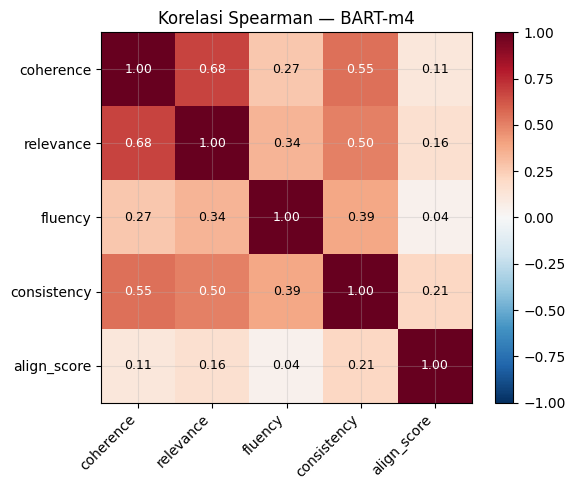


Korelasi fluency vs align_score = 0.042
>> Rendah/negatif ⇒ indikasi 'terbaca bagus tapi tidak faithful' (fokus Tahap 3 #2).


In [12]:
# matriks korelasi Spearman antar metrik
corr = df[METRIC_COLS].corr(method="spearman")
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(METRIC_COLS))); ax.set_xticklabels(METRIC_COLS, rotation=45, ha="right")
ax.set_yticks(range(len(METRIC_COLS))); ax.set_yticklabels(METRIC_COLS)
for i in range(len(METRIC_COLS)):
    for j in range(len(METRIC_COLS)):
        ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center",
                color="white" if abs(corr.iloc[i,j]) > 0.5 else "black", fontsize=9)
plt.colorbar(im, fraction=0.046); plt.title(f"Korelasi Spearman — {PRIMARY}")
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/tahap1_corr.png", dpi=120, bbox_inches="tight")
plt.show()

fa = corr.loc["fluency", "align_score"]
print(f"\nKorelasi fluency vs align_score = {fa:.3f}")
print(">> Rendah/negatif ⇒ indikasi 'terbaca bagus tapi tidak faithful' (fokus Tahap 3 #2)."
      if fa < 0.3 else ">> Korelasi cukup tinggi ⇒ fluency & faithfulness bergerak seiring.")


## Tahap 2 — Stratifikasi + Uji Beda

Memecah skor per-dialog menurut **panjang**, **jumlah turn**, dan **domain**, lalu menguji
apakah perbedaan antar-strata signifikan (ANOVA + Kruskal-Wallis). Tujuannya menemukan
*kapan* model gagal, bukan sekadar seberapa sering.


In [13]:
# bin panjang via kuantil (seimbang)
df = DFS_CLEAN[PRIMARY].copy()
qs = [i/N_LEN_BINS for i in range(1, N_LEN_BINS)]
edges = df["_nwords"].quantile(qs).tolist()
labels_len = ["short", "medium", "long"] if N_LEN_BINS == 3 else [f"bin{i+1}" for i in range(N_LEN_BINS)]
def length_bin(w):
    for i, e in enumerate(edges):
        if w <= e: return labels_len[i]
    return labels_len[-1]
df["_lenbin"] = df["_nwords"].apply(length_bin)
DFS_CLEAN[PRIMARY] = df
print("Batas bin panjang (kata):", [round(e) for e in edges])
print(df["_lenbin"].value_counts().to_dict())


Batas bin panjang (kata): [121, 218]
{'medium': 165, 'short': 160, 'long': 156}


In [14]:
def stratified_table(df, group_col, order=None):
    tab = df.groupby(group_col)[METRIC_COLS].mean()
    if order: tab = tab.reindex([o for o in order if o in tab.index])
    return tab.round(4)

def sig_test(df, group_col, order):
    print(f"Uji beda antar '{group_col}'\n" + "-"*60)
    out = []
    for m in METRIC_COLS:
        groups = [df[df[group_col] == g][m].dropna() for g in order if g in df[group_col].unique()]
        if all(len(g) > 1 for g in groups) and len(groups) > 1:
            F, pf = f_oneway(*groups)
            H, pk = kruskal(*groups)
            sig = "**SIGNIFIKAN**" if pk < 0.05 else "tidak signifikan"
            print(f"  {m:14s} ANOVA p={pf:.3g} | Kruskal p={pk:.3g} -> {sig}")
            out.append({"metric": m, "anova_p": pf, "kruskal_p": pk, "significant": pk < 0.05})
    return pd.DataFrame(out)

# --- per panjang ---
tab_len = stratified_table(df, "_lenbin", labels_len)
print("SKOR PER BIN PANJANG"); display(tab_len)
sig_len = sig_test(df, "_lenbin", labels_len)
tab_len.to_csv(f"{OUTPUT_DIR}/tahap2_by_length.csv")


SKOR PER BIN PANJANG


,coherence,relevance,fluency,consistency,align_score
_lenbin,,,,,
short,0.9309,0.9320,0.8886,0.9137,0.7864
medium,0.9282,0.9123,0.8428,0.9043,0.7953
long,0.9070,0.8806,0.8016,0.8818,0.7623


Uji beda antar '_lenbin'
------------------------------------------------------------
  coherence      ANOVA p=0.0853 | Kruskal p=0.254 -> tidak signifikan
  relevance      ANOVA p=0.00111 | Kruskal p=1.24e-05 -> **SIGNIFIKAN**
  fluency        ANOVA p=4.21e-12 | Kruskal p=1.27e-13 -> **SIGNIFIKAN**
  consistency    ANOVA p=3.39e-05 | Kruskal p=0.000139 -> **SIGNIFIKAN**
  align_score    ANOVA p=0.0495 | Kruskal p=0.0199 -> **SIGNIFIKAN**


In [15]:
# --- per jumlah turn (bin kuantil) ---
df["_turnbin"] = pd.qcut(df["_nturns"], q=min(3, df["_nturns"].nunique()),
                          labels=["few", "mid", "many"][:min(3, df["_nturns"].nunique())],
                          duplicates="drop")
tab_turn = stratified_table(df, "_turnbin", ["few", "mid", "many"])
print("SKOR PER JUMLAH TURN"); display(tab_turn)
sig_turn = sig_test(df, "_turnbin", ["few", "mid", "many"])
DFS_CLEAN[PRIMARY] = df


SKOR PER JUMLAH TURN


,coherence,relevance,fluency,consistency,align_score
_turnbin,,,,,
few,0.9300,0.9370,0.8860,0.9156,0.7873
mid,0.9220,0.9019,0.8354,0.8975,0.8018
many,0.9143,0.8861,0.8115,0.8868,0.7533


Uji beda antar '_turnbin'
------------------------------------------------------------
  coherence      ANOVA p=0.422 | Kruskal p=0.643 -> tidak signifikan
  relevance      ANOVA p=0.00111 | Kruskal p=0.00013 -> **SIGNIFIKAN**
  fluency        ANOVA p=2.84e-09 | Kruskal p=5.55e-11 -> **SIGNIFIKAN**
  consistency    ANOVA p=0.000314 | Kruskal p=0.00119 -> **SIGNIFIKAN**
  align_score    ANOVA p=0.00169 | Kruskal p=0.000781 -> **SIGNIFIKAN**


In [16]:
# --- per domain (explode: dialog multi-domain berkontribusi ke tiap domain) ---
dom_rows = df.explode("_domains").dropna(subset=["_domains"])
tab_dom = dom_rows.groupby("_domains")[METRIC_COLS].mean().round(4)
cnt_dom = dom_rows["_domains"].value_counts()
print("Jumlah (dialog menyentuh) domain:", cnt_dom.to_dict())
print("\nSKOR PER DOMAIN"); display(tab_dom)
sig_dom = sig_test(dom_rows, "_domains", list(cnt_dom.index))
tab_dom.to_csv(f"{OUTPUT_DIR}/tahap2_by_domain.csv")
print("\nCATATAN: deteksi domain berbasis keyword & multi-label ⇒ bingkai sbg 'menyentuh domain X',"
      "\nbukan 'dialog domain X'. Jika selisih kecil, 'tidak ada efek domain' juga temuan sah.")


Jumlah (dialog menyentuh) domain: {'restaurant': 387, 'attraction': 217, 'hotel': 204, 'train': 146, 'taxi': 87}

SKOR PER DOMAIN


,coherence,relevance,fluency,consistency,align_score
_domains,,,,,
attraction,0.9215,0.9046,0.8393,0.8999,0.7725
hotel,0.9177,0.8895,0.8323,0.8919,0.7796
restaurant,0.9245,0.9104,0.8387,0.9001,0.7832
taxi,0.9247,0.9092,0.8020,0.8936,0.7609
train,0.9100,0.8866,0.8191,0.8929,0.7976


Uji beda antar '_domains'
------------------------------------------------------------
  coherence      ANOVA p=0.693 | Kruskal p=0.74 -> tidak signifikan
  relevance      ANOVA p=0.215 | Kruskal p=0.0641 -> tidak signifikan
  fluency        ANOVA p=0.0418 | Kruskal p=0.0345 -> **SIGNIFIKAN**
  consistency    ANOVA p=0.526 | Kruskal p=0.335 -> tidak signifikan
  align_score    ANOVA p=0.171 | Kruskal p=0.167 -> tidak signifikan

CATATAN: deteksi domain berbasis keyword & multi-label ⇒ bingkai sbg 'menyentuh domain X',
bukan 'dialog domain X'. Jika selisih kecil, 'tidak ada efek domain' juga temuan sah.


In [17]:
# tentukan strata "panas": kombinasi bin panjang dgn bottleneck terendah
hot = (df.groupby("_lenbin")[BOTTLENECK].mean().reindex(labels_len))
print(f"Rata-rata {BOTTLENECK} per bin panjang:\n{hot.round(4).to_string()}")
HOT_BIN = hot.idxmin()
print(f"\n>> STRATA PANAS (bottleneck terendah): bin panjang = '{HOT_BIN}'")


Rata-rata align_score per bin panjang:
_lenbin
short     0.7864
medium    0.7953
long      0.7623

>> STRATA PANAS (bottleneck terendah): bin panjang = 'long'


## Tahap 3 — Sampling Terstratifikasi untuk Inspeksi

Memilih contoh **terarah** (bukan acak) untuk lima kelompok diagnostik. Output disimpan ke
CSV/XLSX agar bisa dibaca & dianotasi di Tahap 4.


In [18]:
def show(df, idx, judul):
    print("\n" + "="*78); print(judul); print("="*78)
    for i in idx:
        r = df.loc[i]
        print(f"\n[row {i}]  kata={int(r['_nwords'])} turns={int(r['_nturns'])} | " +
              " ".join(f"{m}={r[m]:.3f}" for m in METRIC_COLS))
        dlg = str(r["_dialogue"]).replace("\n", " | ")
        print("  DIALOG :", textwrap.shorten(dlg, 280))
        if "reference" in df.columns:  print("  REF    :", textwrap.shorten(str(r["reference"]), 220))
        if "prediction" in df.columns: print("  PRED   :", textwrap.shorten(str(r["prediction"]), 220))

df = DFS_CLEAN[PRIMARY]
K = K_SAMPLES
groups = {}

# 1) bottleneck terendah di strata panas
g1 = df[df["_lenbin"] == HOT_BIN].nsmallest(K, BOTTLENECK).index
groups["bottleneck_hot"] = g1
show(df, g1, f"1) {BOTTLENECK} TERENDAH pada bin '{HOT_BIN}' (kapan & bagaimana model gagal?)")



1) align_score TERENDAH pada bin 'long' (kapan & bagaimana model gagal?)

[row 129]  kata=444 turns=26 | coherence=0.925 relevance=0.960 fluency=0.943 consistency=0.890 align_score=0.398
  DIALOG : user: Can you find me a guest house? | agent: Their is Acorn guest house in the north, they are located at 154 chesterton road and their number is 01223353888 | user: Ok is the Acorn guest house a 4 star moderate priced hotel with free parking | agent: Yes, it is a [...]
  REF    : User Profile: Traveler staying in Cambridge who prefers moderate prices, keeps kosher if possible, and is booking accommodation, dining, and transport for two people on a Wednesday. Problem: User needs a moderately [...]
  PRED   : Profile: Traveler planning a stay in the north part of town, interested in moderately priced 4-star guesthouse accommodation with free parking and internet, and using taxis for local transport. Problem: Needed to [...]

[row 328]  kata=374 turns=26 | coherence=0.967 relevance=0.757 flu

In [19]:
# 2) disagreement: fluency tinggi tapi align rendah ("terbaca bagus tapi salah")
z = lambda s: (s - s.mean()) / s.std()
df["_gap_flu_align"] = z(df["fluency"]) - z(df["align_score"])
g2 = df.nlargest(K, "_gap_flu_align").index
groups["fluent_but_wrong"] = g2
show(df, g2, "2) FLUENCY TINGGI tapi ALIGN RENDAH (kasus paling berbahaya)")

# 3) skor rata-rata terendah (sanity: benar buruk atau artefak yg lolos?)
df["_avg"] = df[METRIC_COLS].mean(axis=1)
g3 = df.nsmallest(K, "_avg").index
groups["lowest_avg"] = g3
show(df, g3, "3) SKOR RATA-RATA TERENDAH (sanity check)")

# 4) skor rata-rata tertinggi (sanity positif: bukan menyalin reference?)
g4 = df.nlargest(K, "_avg").index
groups["highest_avg"] = g4
show(df, g4, "4) SKOR RATA-RATA TERTINGGI (sanity check positif)")
DFS_CLEAN[PRIMARY] = df



2) FLUENCY TINGGI tapi ALIGN RENDAH (kasus paling berbahaya)

[row 393]  kata=62 turns=4 | coherence=0.975 relevance=0.979 fluency=0.915 consistency=0.936 align_score=0.332
  DIALOG : user: I want a museum, please? Please include address, postcode, and area. | agent: I suggest Byard art. The address, postcode, and area are 14 king's parade, cb21sj, and it is located in the south. | user: Great. Thanks for all your help. That's all I needed. Goodbye. | [...]
  REF    : User Profile: A user seeking a recommendation for a museum to visit, including location details. Problem: The user wanted a museum recommendation with its address, postcode, and area. Resolution: - Recommended [...]
  PRED   : Profile: User looking for a museum to visit in the south part of town. Problem: User wants a museum recommendation, including its address, postcode, and area, without making a booking. Resolution: - Recommended [...]

[row 129]  kata=444 turns=26 | coherence=0.925 relevance=0.960 fluency=0.943 cons

In [20]:
# 5) outlier antar-arsitektur: |align(A) - align(B)| terbesar pada baris yang sama
#    (hanya jika >=2 eksperimen dgn panjang baris sama)
pair_idx = []
labels_all = list(DFS_CLEAN)
if len(labels_all) >= 2:
    a, b = labels_all[0], labels_all[1]
    da, db = DFS[a], DFS[b]   # pakai versi mentah agar indeks sejajar penuh
    if len(da) == len(db):
        diff = (da["align_score"] - db["align_score"]).abs()
        pair_idx = diff.nlargest(K).index
        print(f"Selisih align terbesar antara {a} vs {b}:")
        for i in pair_idx:
            print(f"  row {i}: {a}={da.loc[i,'align_score']:.3f}  {b}={db.loc[i,'align_score']:.3f}"
                  f"  |Δ|={diff.loc[i]:.3f}")
    else:
        print(f"Lewati: panjang {a} ({len(da)}) != {b} ({len(db)}).")
else:
    print("Lewati kelompok 5: butuh >=2 eksperimen termuat.")


Lewati kelompok 5: butuh >=2 eksperimen termuat.


In [21]:
# ekspor sampel untuk anotasi manual (Tahap 4)
all_idx = sorted(set().union(*[set(ix) for ix in groups.values()]))
cols = (["_nwords", "_nturns", "_lenbin"] + METRIC_COLS +
        [c for c in ["reference", "prediction", "_dialogue"] if c in df.columns])
sample = df.loc[all_idx, cols].copy()
# kolom kosong utk diisi anotator (Tahap 4)
for c in ["err_H_SLOT","err_W_SLOT","err_OMIT","err_REP","err_ROLE","err_OVERGEN","err_COREF","err_STRUCT","catatan"]:
    sample[c] = ""
sample.to_csv(f"{OUTPUT_DIR}/tahap3_sample_for_annotation.csv", index_label="row")
try:
    sample.to_excel(f"{OUTPUT_DIR}/tahap3_sample_for_annotation.xlsx", index_label="row")
except Exception as e:
    print("(.xlsx dilewati:", e, ")")
print(f"Tersimpan {len(sample)} baris ke {OUTPUT_DIR}/tahap3_sample_for_annotation.[csv|xlsx]")
print("Kolom err_* sudah disiapkan kosong untuk diisi anotator (1/0).")


(.xlsx dilewati: Profile:  
User planning a trip to the south part of town, interested in gourmet burger restaurants and local attractions, and using taxis for local transport.

Problem: User wanted information about Gourmet Burger Kitchen and to book a table for 6 people at 13:15 on Tuesday, plus details about nearby attractions (including postcode, attraction type, and entrance fees).

Resolution:
- Confirmed Gourmet Burg Kitchen is an expensive, high-end dining option in the towns centre.  - Booked a table at Gourmet Barbecue Kitchen for 6 at 13; reservation reference provided: K94DWSQN; table held for 6; reference number K94 cannot be used in worksheets. )
Tersimpan 46 baris ke error_analysis_outputs/tahap3_sample_for_annotation.[csv|xlsx]
Kolom err_* sudah disiapkan kosong untuk diisi anotator (1/0).


## Tahap 4 — Taksonomi Error & Anotasi  ⚠️ MANUAL

> **Tahap ini memerlukan manusia.** Sel kode di bawah **sengaja tidak dijalankan** —
> ia hanya scaffold. Langkah kerja:
>
> 1. Buka `tahap3_sample_for_annotation.xlsx`.
> 2. Untuk tiap baris, baca DIALOG / REF / PRED, lalu isi kolom `err_*` dengan `1`/`0`.
> 3. (Disarankan) dua anotator independen → hitung Cohen's κ.
> 4. Simpan kembali sebagai `tahap4_annotated.xlsx`, lalu jalankan sel agregasi di Tahap 5.

**Taksonomi (acuan label):**

| Kode | Tipe Error | Definisi |
|------|-----------|----------|
| `H_SLOT`  | Hallucinated slot value | menambah nilai slot (area, jumlah orang, harga, waktu) yang tidak ada di dialog |
| `W_SLOT`  | Wrong/substituted slot  | nilai slot ada tapi salah (mis. "centre" padahal "east/south") |
| `OMIT`    | Omission                | informasi penting hilang dari ringkasan |
| `REP`     | Repetition/degeneration | frasa/klausa terduplikasi |
| `ROLE`    | Speaker/role confusion  | salah atribusi siapa meminta/mengatakan apa |
| `OVERGEN` | Over-generation         | menambah domain/aktivitas yang tak diminta |
| `COREF`   | Coreference error       | salah resolusi rujukan ("it", "there", "the same") |
| `STRUCT`  | Structural/format error | tidak mengikuti format Profile/Problem/Resolution |


In [22]:
# ===== MANUAL — JANGAN JALANKAN =====
# Scaffold penghitungan inter-annotator agreement (Cohen's kappa) untuk dua anotator.
# Aktifkan HANYA setelah Anda punya dua file anotasi.
#
# from sklearn.metrics import cohen_kappa_score
# ERR = ["H_SLOT","W_SLOT","OMIT","REP","ROLE","OVERGEN","COREF","STRUCT"]
# a1 = pd.read_excel("error_analysis_outputs/tahap4_annotated_rater1.xlsx").set_index("row")
# a2 = pd.read_excel("error_analysis_outputs/tahap4_annotated_rater2.xlsx").set_index("row")
# for e in ERR:
#     k = cohen_kappa_score(a1[f"err_{e}"].fillna(0), a2[f"err_{e}"].fillna(0))
#     print(f"{e:10s} kappa = {k:.3f}")
# # gabungkan (mis. union / mayoritas) jadi label final sebelum agregasi Tahap 5.


In [23]:
# ===== MANUAL — JANGAN JALANKAN =====
# Pedoman anotasi singkat untuk konsistensi antar-anotator (tempel di lembar kerja):
#
# - Satu ringkasan boleh kena >1 kategori. Tandai SEMUA yang berlaku.
# - H_SLOT vs W_SLOT: jika nilai TIDAK ada di dialog -> H_SLOT; jika ADA tapi keliru -> W_SLOT.
# - OVERGEN khusus untuk DOMAIN/aktivitas baru; penambahan detail dalam domain yg benar -> H_SLOT.
# - Repetisi yang murni gaya (bukan duplikasi informasi) tetap REP bila mengganggu keterbacaan.
# - Jika ragu antara dua kategori, catat di kolom `catatan` dan diskusikan saat adjudication.


## Tahap 5 — Perbandingan Antar-Eksperimen

Dua bagian:
- **5a (otomatis):** perbandingan metrik + Δ terhadap baseline, plus **kontrol panjang output**
  (penting agar ROUGE/skor BART vs Qwen comparable).
- **5b (semi-manual):** agregasi tabel **tipe-error × eksperimen** dari hasil anotasi Tahap 4.


In [24]:
# 5a — tabel metrik antar eksperimen (versi bersih) + panjang output
rows = []
for label, df in DFS_CLEAN.items():
    rec = {"experiment": label, "n": len(df)}
    for m in METRIC_COLS:
        rec[m] = round(df[m].mean(skipna=True), 4)
    if "prediction" in df.columns:
        rec["pred_len_words"] = round(df["prediction"].apply(n_words).mean(), 1)
    rows.append(rec)
compare = pd.DataFrame(rows).set_index("experiment")
print("PERBANDINGAN METRIK ANTAR EKSPERIMEN (clean)"); display(compare)

# Δ terhadap baseline bila ada label mengandung 'baseline'
base = next((l for l in compare.index if "baseline" in l.lower()), None)
if base:
    delta = compare[METRIC_COLS] - compare.loc[base, METRIC_COLS]
    print(f"\nΔ relatif terhadap baseline '{base}' (positif = lebih baik):")
    display(delta.round(4))
else:
    print("\n(Tidak ada eksperimen berlabel 'baseline'. Tambahkan ke EXPERIMENTS untuk Δ otomatis.)")
compare.to_csv(f"{OUTPUT_DIR}/tahap5_metric_comparison.csv")


PERBANDINGAN METRIK ANTAR EKSPERIMEN (clean)


,n,coherence,relevance,fluency,consistency,align_score,pred_len_words
experiment,,,,,,,
BART-m4,481,0.9222,0.9086,0.8447,0.9002,0.7817,84.2



(Tidak ada eksperimen berlabel 'baseline'. Tambahkan ke EXPERIMENTS untuk Δ otomatis.)


In [25]:
# 5a — peringatan comparability panjang output (BART vs Qwen)
if "pred_len_words" in compare.columns and len(compare) > 1:
    lo, hi = compare["pred_len_words"].min(), compare["pred_len_words"].max()
    print(f"Panjang prediksi rata-rata: {lo:.1f} – {hi:.1f} kata.")
    if hi > 1.25 * lo:
        print(">> PERINGATAN: selisih panjang output >25%. ROUGE-recall bisa naik artifisial untuk "
              "model yang lebih 'cerewet'. Laporkan panjang ini, atau normalisasi sebelum klaim ROUGE.")
    else:
        print(">> Panjang output relatif setara; perbandingan metrik lebih adil.")


In [26]:
# ===== MANUAL/SEMI-OTOMATIS — JANGAN JALANKAN sebelum Tahap 4 selesai =====
# 5b — agregasi tabel tipe-error x eksperimen dari hasil anotasi.
# Asumsi: tiap eksperimen punya file anotasi 'tahap4_annotated_<label>.xlsx'
# dengan kolom err_* berisi 1/0.
#
# ERR = ["H_SLOT","W_SLOT","OMIT","REP","ROLE","OVERGEN","COREF","STRUCT"]
# agg = {}
# for label in DFS_CLEAN:
#     path = f"error_analysis_outputs/tahap4_annotated_{label}.xlsx"
#     a = pd.read_excel(path)
#     n = len(a)
#     agg[label] = {e: round(100 * a[f"err_{e}"].fillna(0).mean(), 1) for e in ERR}  # % baris terkena
# err_table = pd.DataFrame(agg).T            # baris=eksperimen, kolom=tipe error (%)
# display(err_table)
# err_table.to_csv("error_analysis_outputs/tahap5_error_taxonomy_by_experiment.csv")
#
# # heatmap perbandingan tipe error antar arsitektur:
# import matplotlib.pyplot as plt
# fig, ax = plt.subplots(figsize=(8, 0.6*len(err_table)+2))
# im = ax.imshow(err_table.values, cmap="Reds")
# ax.set_xticks(range(len(ERR))); ax.set_xticklabels(ERR, rotation=45, ha="right")
# ax.set_yticks(range(len(err_table))); ax.set_yticklabels(err_table.index)
# for i in range(len(err_table)):
#     for j in range(len(ERR)):
#         ax.text(j, i, f"{err_table.values[i,j]:.0f}", ha="center", va="center", fontsize=8)
# plt.colorbar(im, fraction=0.046); plt.title("Frekuensi tipe error (%) per eksperimen")
# plt.tight_layout(); plt.show()


## Tahap 6 — Diagnosis Margin Contrastive Learning  ⚠️ MANUAL

> Bagian ini menautkan pola error (Tahap 4–5) ke **mekanisme yang Anda teliti**. Inti-nya adalah
> **audit kualitas negative sample** dan **efek nilai margin** — keduanya butuh akses ke data/konfigurasi
> training, sehingga sel di bawah berupa scaffold yang **tidak dijalankan**.

**Pertanyaan diagnostik:**

1. Apakah *negative samples* berupa **hard negative faktual** (slot value ditukar) atau sekadar
   shuffle/random? Jika bukan faktual, wajar bila `H_SLOT`/`W_SLOT` tetap tinggi meski contrastive aktif.
2. Apakah penurunan tipe error tertentu (mis. `OMIT`) sejalan dengan klaim teoretis margin contrast?
3. Bagaimana hubungan **nilai margin → AlignScore** dan **margin → frekuensi `H_SLOT`**?


In [27]:
# ===== MANUAL — JANGAN JALANKAN =====
# 6.1 Audit negative samples: ambil beberapa contoh (positive, negative) dari data training
#     dan klasifikasikan jenis negative-nya. Sesuaikan path & field dengan pipeline training Anda.
#
# train_pairs = load_json("path/ke/contrastive_training_pairs.json")  # <- sesuaikan
# import random; random.seed(0)
# for ex in random.sample(train_pairs, 10):
#     print("POS:", ex["positive"][:200])
#     print("NEG:", ex["negative"][:200])
#     print("Jenis negative (isi manual): [ ] slot-swap  [ ] omission  [ ] shuffle/acak  [ ] lain")
#     print("-"*60)
#
# Rangkum: berapa % negative yang benar-benar 'hard factual'? Kaitkan dgn tabel error Tahap 5b.


In [28]:
# ===== MANUAL — JANGAN JALANKAN =====
# 6.2 Efek nilai margin (jika Anda melatih beberapa nilai margin).
#     Kumpulkan (margin, mean_align, persen_H_SLOT) per run, lalu plot.
#
# margin_runs = [
#     # {"margin": 0.1, "align": 0.79, "H_SLOT": 22.0},
#     # {"margin": 0.3, "align": 0.81, "H_SLOT": 15.0},
#     # {"margin": 0.5, "align": 0.80, "H_SLOT": 17.0},
# ]
# mr = pd.DataFrame(margin_runs)
# fig, ax1 = plt.subplots(figsize=(6,4))
# ax1.plot(mr["margin"], mr["align"], "o-", color="#4C72B0", label="AlignScore"); ax1.set_xlabel("margin")
# ax1.set_ylabel("AlignScore", color="#4C72B0")
# ax2 = ax1.twinx(); ax2.plot(mr["margin"], mr["H_SLOT"], "s--", color="#C44E52", label="% H_SLOT")
# ax2.set_ylabel("% H_SLOT", color="#C44E52")
# plt.title("Pengaruh margin terhadap faithfulness & halusinasi slot"); plt.tight_layout(); plt.show()


## Tahap 7 — Sintesis & Pelaporan

Bagian otomatis menyiapkan **bahan paper**: kumpulan tabel CSV, satu file ringkas berisi
*error cases* representatif (dialog/ref/pred + skor), dan kerangka temuan. Narasi akhir
(klaim + ancaman validitas) tetap ditulis manusia — disediakan template di sel terakhir.


In [29]:
# kumpulkan error cases representatif untuk ditampilkan di paper
df = DFS_CLEAN[PRIMARY]
showcase_idx = list(dict.fromkeys(
    list(df[df["_lenbin"] == HOT_BIN].nsmallest(3, BOTTLENECK).index) +
    list(df.nlargest(3, "_gap_flu_align").index) +
    list(df.nlargest(2, "_avg").index)
))
cols = ["_nwords", "_nturns", "_lenbin"] + METRIC_COLS + \
       [c for c in ["reference", "prediction", "_dialogue"] if c in df.columns]
showcase = df.loc[showcase_idx, cols]
showcase.to_csv(f"{OUTPUT_DIR}/tahap7_error_cases.csv", index_label="row")
print(f"{len(showcase)} error cases disimpan ke {OUTPUT_DIR}/tahap7_error_cases.csv")

# daftar seluruh artefak yang dihasilkan pipeline
import glob
print("\nArtefak yang dihasilkan:")
for f in sorted(glob.glob(f"{OUTPUT_DIR}/*")):
    print("  -", f)


7 error cases disimpan ke error_analysis_outputs/tahap7_error_cases.csv

Artefak yang dihasilkan:
  - error_analysis_outputs/tahap0_before_after.csv
  - error_analysis_outputs/tahap1_corr.png
  - error_analysis_outputs/tahap1_histograms.png
  - error_analysis_outputs/tahap2_by_domain.csv
  - error_analysis_outputs/tahap2_by_length.csv
  - error_analysis_outputs/tahap3_sample_for_annotation.csv
  - error_analysis_outputs/tahap3_sample_for_annotation.xlsx
  - error_analysis_outputs/tahap5_metric_comparison.csv
  - error_analysis_outputs/tahap7_error_cases.csv


In [30]:
# ringkasan temuan otomatis (angka) — untuk dilengkapi narasi manual
print("="*70); print("RINGKASAN TEMUAN OTOMATIS"); print("="*70)
print(f"- Eksperimen acuan        : {PRIMARY}")
print(f"- Metrik bottleneck       : {BOTTLENECK} (mean={DFS_CLEAN[PRIMARY][BOTTLENECK].mean():.3f})")
print(f"- Strata panjang terburuk : '{HOT_BIN}' untuk {BOTTLENECK}")
if 'sig_len' in dir():
    sigs = sig_len[sig_len['significant']]['metric'].tolist()
    print(f"- Metrik yg beda signifikan antar panjang: {sigs}")
print(f"- Korelasi fluency~align   : {DFS_CLEAN[PRIMARY][['fluency','align_score']].corr(method='spearman').iloc[0,1]:.3f}")
print(f"- Total artefak metrik dibuang ({PRIMARY}): {int(ARTIFACT_FLAGS[PRIMARY]['SUSPECT'].sum())}")


RINGKASAN TEMUAN OTOMATIS
- Eksperimen acuan        : BART-m4
- Metrik bottleneck       : align_score (mean=0.782)
- Strata panjang terburuk : 'long' untuk align_score
- Metrik yg beda signifikan antar panjang: ['relevance', 'fluency', 'consistency', 'align_score']
- Korelasi fluency~align   : 0.042
- Total artefak metrik dibuang (BART-m4): 18


In [31]:
# ===== MANUAL — JANGAN JALANKAN =====
# Template narasi akhir untuk paper (tulis tangan, dukung dgn angka di atas):
#
# TEMUAN UTAMA
#   1. Bottleneck model = faithfulness (AlignScore), bukan fluency/coherence.
#      Bukti: Tahap 1 (distribusi) + Tahap 3 #2 (fluent-but-wrong).
#   2. Degradasi faithfulness pada dialog panjang signifikan (Tahap 2, p<...).
#   3. Pola error dominan: <isi dari Tahap 5b, mis. H_SLOT & OVERGEN>.
#   4. BART vs Qwen: <ringkas perbedaan tipe error + catatan panjang output>.
#   5. Efek margin contrastive: <naik/turun tipe error apa vs baseline; kaitkan ke audit negative>.
#
# PEMISAHAN KETERBATASAN
#   - Keterbatasan MODEL  : <...>
#   - Keterbatasan METRIK : <outlier near-zero UniEval dari Tahap 0; acuan AlignScore>.
#
# ANCAMAN VALIDITAS
#   - Ukuran sampel anotasi & inter-annotator agreement (Cohen's kappa).
#   - Deteksi domain berbasis keyword (multi-label) -> efek domain ditafsir hati-hati.
#   - Bergantung pada satu test split; <jumlah> dialog.
